In [140]:
# IPL Analytics: Impact Player & Match Conditions Analysis

## Project Overview
...

## Main Objective
...

## Data Sources
...

## Analysis Period
...

## Key Metrics
...

## Important Note
...

Ellipsis

## 1. Data Loading

The project uses three main datasets:

- **Batting statistics:** Player-level batting performance.
- **Bowling statistics:** Player-level bowling performance.
- **Match and pitch data:** Ball-by-ball match information with venue and pitch-condition attributes.

Impact Player substitution data is extracted separately from Cricsheet IPL JSON files for the 2023–2025 seasons.

In [141]:
import pandas as pd

batting = pd.read_csv("../data/all_matches_batting_stats.csv")

batting.head()

,match_id,date,batter,batting_team,total_runs,times_out,balls_faced
0,1216492,2020-09-19,AT Rayudu,Chennai Super Kings,71,1,49
1,1216492,2020-09-19,F du Plessis,Chennai Super Kings,58,0,45
2,1216492,2020-09-19,HH Pandya,Mumbai Indians,14,1,10
3,1216492,2020-09-19,JJ Bumrah,Mumbai Indians,5,0,3
4,1216492,2020-09-19,JL Pattinson,Mumbai Indians,11,1,8


In [142]:
batting.info()

<class 'pandas.DataFrame'>
RangeIndex: 5305 entries, 0 to 5304
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   match_id      5305 non-null   int64
 1   date          5305 non-null   str  
 2   batter        5305 non-null   str  
 3   batting_team  5305 non-null   str  
 4   total_runs    5305 non-null   int64
 5   times_out     5305 non-null   int64
 6   balls_faced   5305 non-null   int64
dtypes: int64(4), str(3)
memory usage: 290.2 KB


In [143]:
bowling = pd.read_csv("../data/all_matches_bowling_stats.csv")

bowling.head()


,match_id,date,bowler,wickets,runs_given,overs_bowled
0,1216492,2020-09-19,DL Chahar,2,31,4
1,1216492,2020-09-19,JJ Bumrah,1,41,4
2,1216492,2020-09-19,JL Pattinson,1,26,4
3,1216492,2020-09-19,KH Pandya,1,36,4
4,1216492,2020-09-19,L Ngidi,3,36,4


In [144]:
matches_file = pd.ExcelFile("../data/Ipl match data - enriched.xlsx")

matches_file.sheet_names

['Sheet1']

In [145]:
matches = pd.read_excel(
    "../data/Ipl match data - enriched.xlsx",
    sheet_name="Sheet1"
)

matches.head()

,match_id,date,inning,batting_team,over,ball,batter,non_striker,bowler,runs_batter,...,player_out,dismissal_kind,fielders_involved,stadium,pitch_type,boundary,grass_cover,moisture,dew_prediction,bounce_and_carry
0,1216492,2020-09-19,1,Mumbai Indians,1,1,RG Sharma,Q de Kock,DL Chahar,4,...,NaN,NaN,NaN,Sheikh Zayed Stadium,Sluggish,4.0,Low,Low,High,Sluggish
1,1216492,2020-09-19,1,Mumbai Indians,1,2,RG Sharma,Q de Kock,DL Chahar,1,...,NaN,NaN,NaN,Sheikh Zayed Stadium,Sluggish,NaN,Low,Low,High,Sluggish
2,1216492,2020-09-19,1,Mumbai Indians,1,3,Q de Kock,RG Sharma,DL Chahar,2,...,NaN,NaN,NaN,Sheikh Zayed Stadium,Sluggish,NaN,Low,Low,High,Sluggish
3,1216492,2020-09-19,1,Mumbai Indians,1,4,Q de Kock,RG Sharma,DL Chahar,4,...,NaN,NaN,NaN,Sheikh Zayed Stadium,Sluggish,4.0,Low,Low,High,Sluggish
4,1216492,2020-09-19,1,Mumbai Indians,1,5,Q de Kock,RG Sharma,DL Chahar,0,...,NaN,NaN,NaN,Sheikh Zayed Stadium,Sluggish,NaN,Low,Low,High,Sluggish


## 3. Initial Data Exploration

The datasets were inspected to understand their structure, coverage, and data quality before performing the main analysis.

The initial exploration includes:

- Checking the number of rows and columns.
- Inspecting column names and data types.
- Checking for missing values.
- Examining the date range.
- Identifying the number of unique players and matches.

## 2. Dataset Overview

### Batting Dataset

Contains player-level batting statistics including:

- Match ID
- Date
- Batter
- Batting team
- Total runs
- Times dismissed
- Balls faced

### Bowling Dataset

Contains player-level bowling statistics including:

- Match ID
- Date
- Bowler
- Wickets
- Runs conceded
- Overs bowled

### Match & Pitch Dataset

Contains ball-by-ball match information along with:

- Stadium
- Pitch type
- Grass cover
- Moisture
- Dew prediction
- Bounce & carry
- Runs scored per delivery

### Impact Player Dataset

Impact Player substitution records were extracted from Cricsheet IPL JSON data for the 2023–2025 seasons.

## 4. Impact Player Data Extraction

Impact Player data was extracted from Cricsheet IPL JSON files.

The extraction process identifies match substitutions where the replacement reason is recorded as `impact_player`.

For each Impact Player substitution, the following information was collected:

- Match ID
- Date
- Team
- Player entering the match
- Player leaving the match
- Delivery at which the substitution was recorded

The analysis was restricted to the 2023–2025 IPL seasons because the Impact Player rule was introduced in the IPL in 2023.

The extracted records were saved as `impact_players.csv` for further analysis.

In [146]:
# Look at the structure of the first innings
match["innings"][0].keys()

dict_keys(['team', 'overs', 'powerplays'])

In [147]:
matches.columns.tolist()

['match_id',
 'date',
 'inning',
 'batting_team',
 'over',
 'ball',
 'batter',
 'non_striker',
 'bowler',
 'runs_batter',
 'runs_total',
 'extras_type',
 'player_out',
 'dismissal_kind',
 'fielders_involved',
 'stadium',
 'pitch_type',
 'boundary',
 'grass_cover',
 'moisture',
 'dew_prediction',
 'bounce_and_carry']

In [148]:
matches["date"].min(), matches["date"].max()

('2020-09-19', '2025-03-25')

In [149]:
batting["batter"].nunique()

326

In [150]:
top_run_scorers = (
    batting.groupby("batter")["total_runs"]
    .sum()
    .sort_values(ascending=False)
)

top_run_scorers.head(10)

batter
Shubman Gill    2750
F du Plessis    2747
KL Rahul        2712
V Kohli         2656
RD Gaikwad      2433
SV Samson       2276
JC Buttler      2250
S Dhawan        2190
SA Yadav        2079
Ishan Kishan    2055
Name: total_runs, dtype: int64

In [151]:
batting["match_id"].nunique()

344

In [152]:
from pathlib import Path
import json

json_folder = Path(r"C:\Downloads\ipl_json")

json_files = list(json_folder.glob("*.json"))

len(json_files), json_files[0]

(1243, WindowsPath('C:/Downloads/ipl_json/1082591.json'))

In [153]:
from pathlib import Path
import json

json_folder = Path(r"C:\Downloads\ipl_json")

json_files = list(json_folder.glob("*.json"))

len(json_files), json_files[0]

(1243, WindowsPath('C:/Downloads/ipl_json/1082591.json'))

In [154]:
from pathlib import Path

downloads = Path.home() / "Downloads"

print("Downloads exists:", downloads.exists())
print("Downloads path:", downloads)

print("\nFolders inside Downloads:")
for item in downloads.iterdir():
    if item.is_dir():
        print(item.name)

Downloads exists: True
Downloads path: C:\Users\Aditya\Downloads

Folders inside Downloads:
my code


In [155]:
from pathlib import Path
import json

json_folder = Path(r"C:\Downloads\ipl_json")

json_files = list(json_folder.glob("*.json"))

print("Number of JSON files:", len(json_files))
print("First JSON file:", json_files[0])

Number of JSON files: 1243
First JSON file: C:\Downloads\ipl_json\1082591.json


In [156]:
with open(json_files[0], "r", encoding="utf-8") as f:
    match = json.load(f)

In [157]:
from pathlib import Path

home = Path.home()

matches = list(home.rglob("ipl_json"))

for folder in matches:
    print(folder)
    

In [158]:
from pathlib import Path

home = Path.home()

matches = list(home.rglob("ipl_json"))

for folder in matches:
    print(folder)

In [159]:
from pathlib import Path

json_folder = Path(r"C:\Downloads\ipl_json")

json_files = list(json_folder.glob("*.json"))

print("Number of JSON files:", len(json_files))
print("First JSON file:", json_files[0])

Number of JSON files: 1243
First JSON file: C:\Downloads\ipl_json\1082591.json


In [160]:
import json

with open(json_files[0], "r", encoding="utf-8") as f:
    match = json.load(f)

match.keys()

dict_keys(['meta', 'info', 'innings'])

In [161]:
# Look at the structure of the first innings
match["innings"][0].keys()

dict_keys(['team', 'overs', 'powerplays'])

In [162]:
match["innings"][0]["overs"][0]["deliveries"][0]

{'actual_delivery': '0.1',
 'batter': 'DA Warner',
 'bowler': 'TS Mills',
 'non_striker': 'S Dhawan',
 'runs': {'batter': 0, 'extras': 0, 'total': 0}}

In [163]:
impact_files = []

for file in json_files:
    with open(file, "r", encoding="utf-8") as f:
        data = f.read()

    if "impact_player" in data:
        impact_files.append(file)

print("Matches containing Impact Player data:", len(impact_files))

if impact_files:
    print("First match:", impact_files[0])

Matches containing Impact Player data: 291
First match: C:\Downloads\ipl_json\1359475.json


In [164]:
impact_file = impact_files[0]

with open(impact_file, "r", encoding="utf-8") as f:
    impact_match = json.load(f)

# Find and display the first Impact Player occurrence
for innings in impact_match["innings"]:
    for over in innings["overs"]:
        for delivery in over["deliveries"]:
            if "impact_player" in json.dumps(delivery):
                print(delivery)
                break

{'actual_delivery': '0.1', 'batter': 'WP Saha', 'bowler': 'DL Chahar', 'non_striker': 'Shubman Gill', 'replacements': {'match': [{'in': 'TU Deshpande', 'out': 'AT Rayudu', 'team': 'Chennai Super Kings', 'reason': 'impact_player'}]}, 'runs': {'batter': 0, 'extras': 0, 'total': 0}}
{'actual_delivery': '3.6', 'batter': 'B Sai Sudharsan', 'bowler': 'RS Hangargekar', 'non_striker': 'Shubman Gill', 'replacements': {'match': [{'in': 'B Sai Sudharsan', 'out': 'KS Williamson', 'team': 'Gujarat Titans', 'reason': 'impact_player'}]}, 'runs': {'batter': 4, 'extras': 0, 'total': 4}}


In [165]:
print("Match ID:", impact_file.stem)
print("Date:", impact_match["info"]["dates"])
print("Teams:", impact_match["info"]["teams"])

Match ID: 1359475
Date: ['2023-03-31']
Teams: ['Chennai Super Kings', 'Gujarat Titans']


In [166]:
import pandas as pd

impact_records = []

for file in json_files:
    with open(file, "r", encoding="utf-8") as f:
        data = json.load(f)

    match_id = file.stem
    date = data["info"]["dates"][0]

    for innings in data["innings"]:
        for over in innings["overs"]:
            for delivery in over["deliveries"]:

                if "replacements" not in delivery:
                    continue

                replacements = delivery["replacements"].get("match", [])

                for replacement in replacements:

                    if replacement.get("reason") == "impact_player":

                        impact_records.append({
                            "match_id": match_id,
                            "date": date,
                            "team": replacement.get("team"),
                            "player_in": replacement.get("in"),
                            "player_out": replacement.get("out"),
                            "impact_over": delivery.get("actual_delivery")
                        })

impact_players = pd.DataFrame(impact_records)

impact_players.head(10)

,match_id,date,team,player_in,player_out,impact_over
0,1359475,2023-03-31,Chennai Super Kings,TU Deshpande,AT Rayudu,0.1
1,1359475,2023-03-31,Gujarat Titans,B Sai Sudharsan,KS Williamson,3.6
2,1359476,2023-04-01,Punjab Kings,R Dhawan,PBB Rajapaksa,0.1
3,1359476,2023-04-01,Kolkata Knight Riders,VR Iyer,CV Varun,2.1
4,1359477,2023-04-01,Delhi Capitals,Aman Hakim Khan,KK Ahmed,19.1
5,1359477,2023-04-01,Lucknow Super Giants,K Gowtham,A Badoni,19.6
6,1359478,2023-04-02,Sunrisers Hyderabad,Abdul Samad,Fazalhaq Farooqi,9.4
7,1359478,2023-04-02,Rajasthan Royals,NA Saini,YBK Jaiswal,11.1
8,1359479,2023-04-02,Mumbai Indians,JP Behrendorff,SA Yadav,0.1
9,1359480,2023-04-03,Lucknow Super Giants,A Badoni,Avesh Khan,19.1


### Extracted Impact Player Records

The extracted Impact Player records were summarized to verify the number of substitutions, unique matches, date coverage, and records across seasons.

The final analysis is restricted to the 2023–2025 IPL seasons.

In [167]:
print("Total Impact Player records:", len(impact_players))
print("Unique matches:", impact_players["match_id"].nunique())
print("Date range:", impact_players["date"].min(), "to", impact_players["date"].max())
print("\nRecords by year:")
print(pd.to_datetime(impact_players["date"]).dt.year.value_counts().sort_index())

Total Impact Player records: 557
Unique matches: 291
Date range: 2023-03-31 to 2026-05-31

Records by year:
date
2023    139
2024    137
2025    141
2026    140
Name: count, dtype: int64


### Filtering the Analysis Period

Cricsheet data also contains later IPL seasons. Since this project focuses on the introduction and early use of the Impact Player rule, the analysis is restricted to IPL seasons from 2023 to 2025.

The Impact Player rule was introduced in the IPL in 2023.

In [168]:
impact_players["date"] = pd.to_datetime(impact_players["date"])

impact_players = impact_players[
    impact_players["date"].dt.year <= 2025
].copy()

print("Impact Player records:", len(impact_players))
print("Unique matches:", impact_players["match_id"].nunique())
print("\nRecords by year:")
print(impact_players["date"].dt.year.value_counts().sort_index())

Impact Player records: 417
Unique matches: 218

Records by year:
date
2023    139
2024    137
2025    141
Name: count, dtype: int64


In [169]:
impact_players.to_csv("../data/impact_players.csv", index=False)

print("Saved successfully!")
print("File:", "../data/impact_players.csv")

Saved successfully!
File: ../data/impact_players.csv


In [170]:
impact_players.head()

,match_id,date,team,player_in,player_out,impact_over
0,1359475,2023-03-31,Chennai Super Kings,TU Deshpande,AT Rayudu,0.1
1,1359475,2023-03-31,Gujarat Titans,B Sai Sudharsan,KS Williamson,3.6
2,1359476,2023-04-01,Punjab Kings,R Dhawan,PBB Rajapaksa,0.1
3,1359476,2023-04-01,Kolkata Knight Riders,VR Iyer,CV Varun,2.1
4,1359477,2023-04-01,Delhi Capitals,Aman Hakim Khan,KK Ahmed,19.1


In [171]:
import os

print(os.path.exists("../data/impact_players.csv"))

True


## 5. Impact Player Usage Analysis

The frequency of Impact Player usage was analyzed to identify players who were most frequently brought into matches as Impact Players during the 2023–2025 seasons.

This helps identify players who were regularly used as tactical substitutions by their teams.

In [172]:
impact_in_count = (
    impact_players["player_in"]
    .value_counts()
)

impact_in_count.head(15)

player_in
P Simran Singh     16
Suyash Sharma      14
S Dube             12
A Badoni           10
RG Sharma           9
B Sai Sudharsan     8
D Padikkal          8
M Pathirana         8
A Raghuvanshi       8
SB Dubey            8
VG Arora            7
Ashutosh Sharma     7
TM Head             7
AT Rayudu           6
Abishek Porel       6
Name: count, dtype: int64

### Key Observation

The analysis shows that P Simran Singh was the most frequently used Impact Player during the 2023–2025 period, followed by Suyash Sharma and S Dube.

This indicates that some players were consistently used as tactical substitutes across multiple matches.

However, frequency of use alone does not indicate performance. Therefore, the next analysis compares Impact Player performance with the same player's normal appearances.

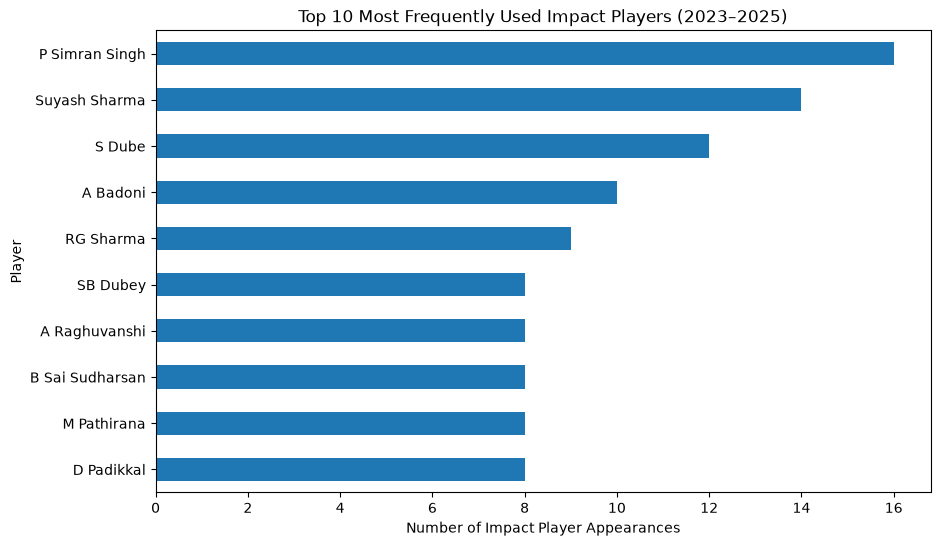

In [173]:
import matplotlib.pyplot as plt

top_impact_players = impact_in_count.head(10)

plt.figure(figsize=(10, 6))
top_impact_players.sort_values().plot(kind="barh")

plt.title("Top 10 Most Frequently Used Impact Players (2023–2025)")
plt.xlabel("Number of Impact Player Appearances")
plt.ylabel("Player")

plt.show()

## 6. Impact Player Batting Analysis

To evaluate batting performance, Impact Player substitution records were matched with player-level batting statistics using the match ID and player name.

This allows us to identify whether an Impact Player batted in the match and measure their runs, balls faced, and strike rate.

Not every Impact Player is expected to have batting data because some players may have been introduced primarily for their bowling role.

In [174]:
# Make sure match_id has the same data type in both datasets
impact_players["match_id"] = impact_players["match_id"].astype(int)

impact_batting = impact_players.merge(
    batting,
    left_on=["match_id", "player_in"],
    right_on=["match_id", "batter"],
    how="left"
)

impact_batting[
    [
        "match_id",
        "date_x",
        "team",
        "player_in",
        "player_out",
        "total_runs",
        "balls_faced"
    ]
].head(10)

,match_id,date_x,team,player_in,player_out,total_runs,balls_faced
0,1359475,2023-03-31,Chennai Super Kings,TU Deshpande,AT Rayudu,NaN,NaN
1,1359475,2023-03-31,Gujarat Titans,B Sai Sudharsan,KS Williamson,22.0,17.0
2,1359476,2023-04-01,Punjab Kings,R Dhawan,PBB Rajapaksa,NaN,NaN
3,1359476,2023-04-01,Kolkata Knight Riders,VR Iyer,CV Varun,34.0,29.0
4,1359477,2023-04-01,Delhi Capitals,Aman Hakim Khan,KK Ahmed,4.0,5.0
5,1359477,2023-04-01,Lucknow Super Giants,K Gowtham,A Badoni,6.0,1.0
6,1359478,2023-04-02,Sunrisers Hyderabad,Abdul Samad,Fazalhaq Farooqi,32.0,33.0
7,1359478,2023-04-02,Rajasthan Royals,NA Saini,YBK Jaiswal,NaN,NaN
8,1359479,2023-04-02,Mumbai Indians,JP Behrendorff,SA Yadav,NaN,NaN
9,1359480,2023-04-03,Lucknow Super Giants,A Badoni,Avesh Khan,23.0,19.0


In [175]:
impact_players["match_id"] = impact_players["match_id"].astype(int)

print(impact_players["match_id"].dtype)
print(batting["match_id"].dtype)

int64
int64


### Impact Player Contribution Types

Impact Player appearances were classified according to the recorded batting and bowling statistics.

The classification shows whether an Impact Player contributed through batting, bowling, both, or had no recorded contribution in the available scorecard data.

This distinction is important because an Impact Player may be introduced for a specific tactical role and may not necessarily bat or bowl in every match.

In [176]:
impact_batting = impact_players.merge(
    batting,
    left_on=["match_id", "player_in"],
    right_on=["match_id", "batter"],
    how="left"
)

impact_batting[
    ["match_id", "date_x", "team", "player_in", "player_out",
     "total_runs", "balls_faced"]
].head(10)

,match_id,date_x,team,player_in,player_out,total_runs,balls_faced
0,1359475,2023-03-31,Chennai Super Kings,TU Deshpande,AT Rayudu,NaN,NaN
1,1359475,2023-03-31,Gujarat Titans,B Sai Sudharsan,KS Williamson,22.0,17.0
2,1359476,2023-04-01,Punjab Kings,R Dhawan,PBB Rajapaksa,NaN,NaN
3,1359476,2023-04-01,Kolkata Knight Riders,VR Iyer,CV Varun,34.0,29.0
4,1359477,2023-04-01,Delhi Capitals,Aman Hakim Khan,KK Ahmed,4.0,5.0
5,1359477,2023-04-01,Lucknow Super Giants,K Gowtham,A Badoni,6.0,1.0
6,1359478,2023-04-02,Sunrisers Hyderabad,Abdul Samad,Fazalhaq Farooqi,32.0,33.0
7,1359478,2023-04-02,Rajasthan Royals,NA Saini,YBK Jaiswal,NaN,NaN
8,1359479,2023-04-02,Mumbai Indians,JP Behrendorff,SA Yadav,NaN,NaN
9,1359480,2023-04-03,Lucknow Super Giants,A Badoni,Avesh Khan,23.0,19.0


In [177]:
print("Total Impact Player records:", len(impact_batting))

print("Had batting data:", impact_batting["total_runs"].notna().sum())
print("No batting data:", impact_batting["total_runs"].isna().sum())

Total Impact Player records: 417
Had batting data: 162
No batting data: 255


In [178]:
# Make sure match_id has the same data type in both datasets
impact_players["match_id"] = impact_players["match_id"].astype(int)

# Merge Impact Player data with bowling statistics
impact_bowling = impact_players.merge(
    bowling,
    left_on=["match_id", "player_in"],
    right_on=["match_id", "bowler"],
    how="left"
)

# Display the first 10 records
impact_bowling[
    [
        "match_id",
        "date_x",
        "team",
        "player_in",
        "player_out",
        "wickets",
        "runs_given",
        "overs_bowled"
    ]
].head(10)

,match_id,date_x,team,player_in,player_out,wickets,runs_given,overs_bowled
0,1359475,2023-03-31,Chennai Super Kings,TU Deshpande,AT Rayudu,1.0,49.0,4.0
1,1359475,2023-03-31,Gujarat Titans,B Sai Sudharsan,KS Williamson,NaN,NaN,NaN
2,1359476,2023-04-01,Punjab Kings,R Dhawan,PBB Rajapaksa,0.0,15.0,1.0
3,1359476,2023-04-01,Kolkata Knight Riders,VR Iyer,CV Varun,NaN,NaN,NaN
4,1359477,2023-04-01,Delhi Capitals,Aman Hakim Khan,KK Ahmed,NaN,NaN,NaN
5,1359477,2023-04-01,Lucknow Super Giants,K Gowtham,A Badoni,0.0,22.0,4.0
6,1359478,2023-04-02,Sunrisers Hyderabad,Abdul Samad,Fazalhaq Farooqi,NaN,NaN,NaN
7,1359478,2023-04-02,Rajasthan Royals,NA Saini,YBK Jaiswal,0.0,31.0,2.0
8,1359479,2023-04-02,Mumbai Indians,JP Behrendorff,SA Yadav,0.0,37.0,3.0
9,1359480,2023-04-03,Lucknow Super Giants,A Badoni,Avesh Khan,NaN,NaN,NaN


In [179]:
impact_analysis = impact_batting.merge(
    impact_bowling[
        ["match_id", "player_in", "wickets", "runs_given", "overs_bowled"]
    ],
    on=["match_id", "player_in"],
    how="left"
)

def classify_contribution(row):
    batting = pd.notna(row["total_runs"])
    bowling = pd.notna(row["overs_bowled"])

    if batting and bowling:
        return "Both"
    elif batting:
        return "Batting"
    elif bowling:
        return "Bowling"
    else:
        return "No recorded contribution"

impact_analysis["contribution_type"] = impact_analysis.apply(
    classify_contribution,
    axis=1
)

print(impact_analysis["contribution_type"].value_counts())

contribution_type
Batting                     148
No recorded contribution    144
Bowling                     111
Both                         14
Name: count, dtype: int64


### Batting Performance Metrics

For Impact Player batting appearances, two key performance measures were examined:

- **Average runs per appearance** — the average number of runs scored by an Impact Player when they batted.
- **Strike rate** — runs scored per 100 balls faced.

Both metrics help evaluate batting output and scoring efficiency.

In [180]:
impact_batting_stats = impact_analysis[
    impact_analysis["total_runs"].notna()
].copy()

impact_batting_stats["strike_rate"] = (
    impact_batting_stats["total_runs"]
    / impact_batting_stats["balls_faced"]
    * 100
)

print("Batting Impact Player appearances:", len(impact_batting_stats))
print("Average runs:", round(impact_batting_stats["total_runs"].mean(), 2))
print("Average strike rate:", round(impact_batting_stats["strike_rate"].mean(), 2))

Batting Impact Player appearances: 162
Average runs: 18.41
Average strike rate: 116.96


### Key Batting Findings

Among the 162 Impact Player appearances with recorded batting data, the average runs scored per appearance was 18.41.

The average of individual match-level strike rates was 116.96. However, for the overall Impact Player group, aggregate strike rate is more appropriate because it is calculated from total runs and total balls faced.

The aggregate results were:

- Total runs: 2,983
- Total balls faced: 2,245
- Overall strike rate: 132.87

These figures provide a baseline for evaluating Impact Player batting performance. The next step compares these players with their own normal appearances to make the comparison more meaningful.

In [181]:
total_runs = impact_batting_stats["total_runs"].sum()
total_balls = impact_batting_stats["balls_faced"].sum()

overall_strike_rate = (total_runs / total_balls) * 100

print("Total runs:", int(total_runs))
print("Total balls:", int(total_balls))
print("Overall strike rate:", round(overall_strike_rate, 2))

Total runs: 2983
Total balls: 2245
Overall strike rate: 132.87


## 7. Impact Player vs Normal Performance

To make the performance comparison more meaningful, Impact Player appearances are compared with the same player's normal batting appearances.

A match is treated as an Impact Player appearance when the player entered that match as an Impact Player. The same player's other batting appearances are treated as normal appearances.

This player-vs-self comparison helps reduce differences caused by comparing completely different players.

In [182]:
# Create a key for Impact Player batting appearances
impact_keys = set(
    zip(
        impact_batting_stats["match_id"],
        impact_batting_stats["player_in"]
    )
)

print("Impact batting match-player combinations:", len(impact_keys))

Impact batting match-player combinations: 162


### Creating the Normal Performance Baseline

The normal-performance baseline was created by removing the matches in which a player was used as an Impact Player.

This ensures that a player's Impact Player matches are not included in their normal-performance baseline.

The comparison therefore focuses on the same player's performance in two situations:

- **Impact Player appearance**
- **Normal appearance**

This player-vs-self approach provides a more meaningful comparison than comparing Impact Players with all IPL players.

In [183]:
# Create a key for every batting appearance
batting_keys = list(zip(batting["match_id"], batting["batter"]))

# Keep only batting appearances that were NOT as an Impact Player
non_impact_batting = batting[
    ~pd.Series(batting_keys).isin(impact_keys).values
].copy()

print("Total batting records:", len(batting))
print("Non-Impact batting records:", len(non_impact_batting))

Total batting records: 5305
Non-Impact batting records: 5143


### Normal Batting Baseline

After removing the player's Impact Player appearances, the remaining batting records were used as the normal-performance baseline.

This baseline represents the player's regular batting appearances during the available dataset period.

The normal baseline is used to calculate average runs and overall strike rate for comparison with Impact Player appearances.

In [184]:
non_impact_runs = non_impact_batting["total_runs"].sum()
non_impact_balls = non_impact_batting["balls_faced"].sum()

non_impact_avg_runs = non_impact_batting["total_runs"].mean()
non_impact_strike_rate = (
    non_impact_runs / non_impact_balls
) * 100

print("Average runs:", round(non_impact_avg_runs, 2))
print("Overall strike rate:", round(non_impact_strike_rate, 2))

Average runs: 20.89
Overall strike rate: 132.89


In [185]:
impact_player_frequency = (
    impact_players["player_in"]
    .value_counts()
)

impact_player_frequency[
    impact_player_frequency >= 5
]

player_in
P Simran Singh     16
Suyash Sharma      14
S Dube             12
A Badoni           10
RG Sharma           9
B Sai Sudharsan     8
D Padikkal          8
M Pathirana         8
A Raghuvanshi       8
SB Dubey            8
VG Arora            7
Ashutosh Sharma     7
TM Head             7
AT Rayudu           6
Abishek Porel       6
SE Rutherford       6
VR Iyer             5
PP Shaw             5
KV Sharma           5
Mukesh Kumar        5
Akash Singh         5
NT Ellis            5
Rasikh Salam        5
I Sharma            5
Name: count, dtype: int64

In [186]:
impact_batting_frequency = (
    impact_batting_stats["player_in"]
    .value_counts()
)

impact_batting_frequency[
    impact_batting_frequency >= 3
]

player_in
P Simran Singh      11
B Sai Sudharsan      5
VR Iyer              5
A Badoni             5
PP Shaw              5
AT Rayudu            5
D Padikkal           5
S Dube               5
V Shankar            4
RG Sharma            4
RA Tripathi          4
Shubman Gill         4
SA Yadav             4
Abishek Porel        4
Ashutosh Sharma      4
JC Buttler           4
Abdul Samad          3
Anuj Rawat           3
AS Roy               3
N Wadhera            3
Anmolpreet Singh     3
MK Pandey            3
TM Head              3
Sameer Rizvi         3
Swapnil Singh        3
Name: count, dtype: int64

In [187]:
qualified_players = impact_batting_frequency[
    impact_batting_frequency >= 3
].index.tolist()

print("Number of qualified players:", len(qualified_players))
print(qualified_players)

Number of qualified players: 25
['P Simran Singh', 'B Sai Sudharsan', 'VR Iyer', 'A Badoni', 'PP Shaw', 'AT Rayudu', 'D Padikkal', 'S Dube', 'V Shankar', 'RG Sharma', 'RA Tripathi', 'Shubman Gill', 'SA Yadav', 'Abishek Porel', 'Ashutosh Sharma', 'JC Buttler', 'Abdul Samad', 'Anuj Rawat', 'AS Roy', 'N Wadhera', 'Anmolpreet Singh', 'MK Pandey', 'TM Head', 'Sameer Rizvi', 'Swapnil Singh']


In [188]:
# Keep normal batting appearances of our 25 qualified players
normal_batting = batting[
    batting["batter"].isin(qualified_players)
].copy()

# Remove the appearances where they were Impact Players
normal_batting["impact_key"] = list(
    zip(normal_batting["match_id"], normal_batting["batter"])
)

normal_batting = normal_batting[
    ~normal_batting["impact_key"].isin(impact_keys)
].copy()

print("Normal batting appearances:", len(normal_batting))

Normal batting appearances: 816


## 8. Player-Level Performance Comparison

The batting performance of selected Impact Players was compared with their normal batting performance.

To improve reliability, only players with at least **5 Impact Player batting appearances** were included in the final comparison.

The comparison uses:

- Average runs per appearance
- Overall strike rate
- Number of appearances

This helps identify players whose batting performance was higher or lower when used as an Impact Player.

In [189]:
# Impact Player batting summary
impact_summary = (
    impact_batting_stats[
        impact_batting_stats["player_in"].isin(qualified_players)
    ]
    .groupby("player_in")
    .agg(
        impact_appearances=("total_runs", "count"),
        impact_avg_runs=("total_runs", "mean"),
        impact_runs=("total_runs", "sum"),
        impact_balls=("balls_faced", "sum")
    )
)

impact_summary["impact_sr"] = (
    impact_summary["impact_runs"] /
    impact_summary["impact_balls"] * 100
)

# Normal batting summary
normal_summary = (
    normal_batting
    .groupby("batter")
    .agg(
        normal_appearances=("total_runs", "count"),
        normal_avg_runs=("total_runs", "mean"),
        normal_runs=("total_runs", "sum"),
        normal_balls=("balls_faced", "sum")
    )
)

normal_summary["normal_sr"] = (
    normal_summary["normal_runs"] /
    normal_summary["normal_balls"] * 100
)

# Combine both
player_comparison = impact_summary.join(
    normal_summary,
    how="left"
)

player_comparison

,impact_appearances,impact_avg_runs,impact_runs,impact_balls,impact_sr,normal_appearances,normal_avg_runs,normal_runs,normal_balls,normal_sr
player_in,,,,,,,,,,
A Badoni,5,16.800000,84.0,80.0,105.000000,31,17.870968,554,430,128.837209
AS Roy,3,5.333333,16.0,11.0,145.454545,3,3.333333,10,13,76.923077
AT Rayudu,5,8.400000,42.0,41.0,102.439024,42,23.952381,1006,768,130.989583
Abdul Samad,3,15.000000,45.0,52.0,86.538462,36,14.833333,534,356,150.000000
Abishek Porel,4,14.000000,56.0,33.0,169.696970,13,23.384615,304,213,142.723005
Anmolpreet Singh,3,12.666667,38.0,30.0,126.666667,6,16.833333,101,87,116.091954
Anuj Rawat,3,13.666667,41.0,42.0,97.619048,18,15.388889,277,234,118.376068
Ashutosh Sharma,4,36.250000,145.0,75.0,193.333333,6,18.333333,110,74,148.648649
B Sai Sudharsan,5,40.000000,200.0,163.0,122.699387,21,43.238095,908,651,139.477727


In [190]:
player_comparison["run_difference"] = (
    player_comparison["impact_avg_runs"]
    - player_comparison["normal_avg_runs"]
)

player_comparison["sr_difference"] = (
    player_comparison["impact_sr"]
    - player_comparison["normal_sr"]
)

player_comparison[
    [
        "impact_appearances",
        "impact_avg_runs",
        "normal_avg_runs",
        "run_difference",
        "impact_sr",
        "normal_sr",
        "sr_difference"
    ]
].sort_values("run_difference", ascending=False)

,impact_appearances,impact_avg_runs,normal_avg_runs,run_difference,impact_sr,normal_sr,sr_difference
player_in,,,,,,,
Ashutosh Sharma,4,36.250000,18.333333,17.916667,193.333333,148.648649,44.684685
V Shankar,4,26.500000,16.740741,9.759259,130.864198,118.947368,11.916829
Sameer Rizvi,3,12.333333,6.000000,6.333333,102.777778,163.636364,-60.858586
VR Iyer,5,31.200000,26.133333,5.066667,145.794393,130.521643,15.272750
RG Sharma,4,29.500000,24.454545,5.045455,126.881720,126.291080,0.590641
SA Yadav,4,36.000000,31.721311,4.278689,214.925373,150.583658,64.341716
JC Buttler,4,40.250000,36.017241,4.232759,147.706422,140.201342,7.505080
P Simran Singh,11,24.454545,20.695652,3.758893,153.714286,138.775510,14.938776
AS Roy,3,5.333333,3.333333,2.000000,145.454545,76.923077,68.531469


### Measuring Performance Change

To identify the change in performance, two difference measures were calculated:

- **Run Difference** = Impact Player average runs − Normal average runs
- **Strike Rate Difference** = Impact Player strike rate − Normal strike rate

A positive value indicates that the player's metric was higher during Impact Player appearances, while a negative value indicates lower performance compared with their normal appearances.

These differences help identify players who performed better or worse in the Impact Player role.

In [191]:
reliable_comparison = player_comparison[
    player_comparison["impact_appearances"] >= 5
].copy()

reliable_comparison[
    [
        "impact_appearances",
        "impact_avg_runs",
        "normal_avg_runs",
        "run_difference",
        "impact_sr",
        "normal_sr",
        "sr_difference"
    ]
].sort_values("run_difference", ascending=False)

,impact_appearances,impact_avg_runs,normal_avg_runs,run_difference,impact_sr,normal_sr,sr_difference
player_in,,,,,,,
VR Iyer,5,31.200000,26.133333,5.066667,145.794393,130.521643,15.272750
P Simran Singh,11,24.454545,20.695652,3.758893,153.714286,138.775510,14.938776
A Badoni,5,16.800000,17.870968,-1.070968,105.000000,128.837209,-23.837209
S Dube,5,23.800000,25.509434,-1.709434,113.333333,142.766631,-29.433298
B Sai Sudharsan,5,40.000000,43.238095,-3.238095,122.699387,139.477727,-16.778340
D Padikkal,5,15.800000,24.833333,-9.033333,97.530864,119.009585,-21.478720
AT Rayudu,5,8.400000,23.952381,-15.552381,102.439024,130.989583,-28.550559
PP Shaw,5,6.800000,25.714286,-18.914286,121.428571,146.853147,-25.424575


### Filtering for Reliable Comparisons

To avoid drawing conclusions from very small samples, the final comparison was limited to players with at least 5 Impact Player batting appearances.

This produced a smaller group of players for whom the Impact Player vs normal-performance comparison is more meaningful.

Even with this filter, the results should be interpreted as observed patterns rather than proof that the Impact Player role caused the performance change.

### Visualizing Change in Average Runs

The change in average runs between Impact Player and normal appearances is visualized using a horizontal bar chart.

- Values **above 0** indicate an increase in average runs as an Impact Player.
- Values **below 0** indicate a decrease in average runs.
- The zero reference line represents no change.

This visualization makes it easier to identify which players showed an increase or decrease in average batting performance.

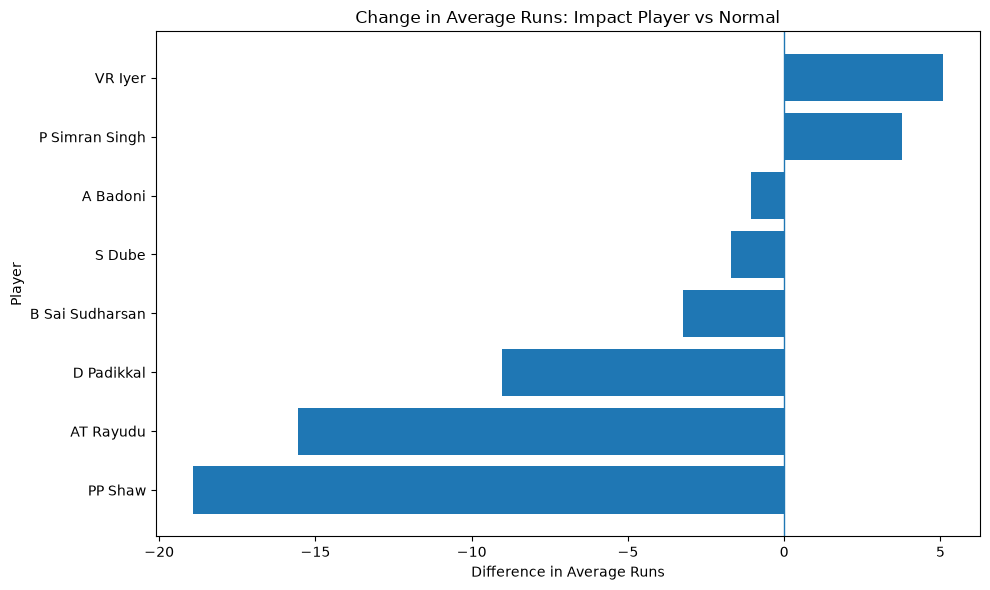

In [192]:
import matplotlib.pyplot as plt

plot_data = reliable_comparison.sort_values("run_difference")

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data.index,
    plot_data["run_difference"]
)

plt.axvline(0, linewidth=1)

plt.title("Change in Average Runs: Impact Player vs Normal")
plt.xlabel("Difference in Average Runs")
plt.ylabel("Player")

plt.tight_layout()
plt.show()

### Key Observation

Among the players with at least 5 Impact Player batting appearances, VR Iyer and P Simran Singh showed an increase in average runs when used as Impact Players.

The remaining players in the comparison showed lower average runs in their Impact Player appearances than in their normal appearances.

This suggests that the Impact Player role does not automatically improve batting performance. Player performance can vary depending on role, match situation, batting position, opposition, and team strategy.

## 9. Impact Player Bowling Analysis

The same approach was used to analyze bowling performance.

Impact Player substitutions were matched with bowling statistics using the match ID and player name.

For players who bowled as Impact Players, the analysis examines:

- Wickets
- Runs conceded
- Overs bowled
- Bowling economy
- Wickets per appearance

These metrics are then compared with the same player's normal bowling appearances.

In [193]:
impact_bowling_frequency = (
    impact_bowling[
        impact_bowling["overs_bowled"].notna()
    ]["player_in"]
    .value_counts()
)

impact_bowling_frequency[
    impact_bowling_frequency >= 5
]

player_in
Suyash Sharma    8
M Pathirana      6
NT Ellis         5
VG Arora         5
Name: count, dtype: int64

In [194]:
qualified_bowlers = impact_bowling_frequency[
    impact_bowling_frequency >= 5
].index.tolist()

print("Qualified bowlers:", qualified_bowlers)

Qualified bowlers: ['Suyash Sharma', 'M Pathirana', 'NT Ellis', 'VG Arora']


### Qualified Impact Player Bowlers

To make the bowling comparison more reliable, only players with at least 5 Impact Player bowling appearances were selected.

This resulted in four qualified bowlers:

- Suyash Sharma
- M Pathirana
- NT Ellis
- VG Arora

These players are used for the detailed Impact Player vs normal bowling comparison.

### Creating the Normal Bowling Baseline

The normal bowling baseline was created by selecting the same qualified bowlers' regular bowling appearances.

Their Impact Player bowling appearances were then excluded from this baseline.

This allows us to compare each bowler with their own performance in normal appearances rather than comparing different players.

In [195]:
# All bowling appearances of these players
normal_bowling = bowling[
    bowling["bowler"].isin(qualified_bowlers)
].copy()

# Create match-player key
normal_bowling["impact_key"] = list(
    zip(normal_bowling["match_id"], normal_bowling["bowler"])
)

# Remove matches where they were Impact Players
normal_bowling = normal_bowling[
    ~normal_bowling["impact_key"].isin(
        set(zip(impact_bowling["match_id"], impact_bowling["player_in"]))
    )
].copy()

print("Normal bowling appearances:", len(normal_bowling))

Normal bowling appearances: 48


In [196]:
# Impact Player bowling summary
impact_bowling_summary = (
    impact_bowling[
        impact_bowling["player_in"].isin(qualified_bowlers)
        & impact_bowling["overs_bowled"].notna()
    ]
    .groupby("player_in")
    .agg(
        impact_appearances=("wickets", "count"),
        impact_wickets=("wickets", "sum"),
        impact_runs_given=("runs_given", "sum"),
        impact_overs=("overs_bowled", "sum")
    )
)

# Economy rate
impact_bowling_summary["impact_economy"] = (
    impact_bowling_summary["impact_runs_given"]
    / impact_bowling_summary["impact_overs"]
)

# Normal bowling summary
normal_bowling_summary = (
    normal_bowling
    .groupby("bowler")
    .agg(
        normal_appearances=("wickets", "count"),
        normal_wickets=("wickets", "sum"),
        normal_runs_given=("runs_given", "sum"),
        normal_overs=("overs_bowled", "sum")
    )
)

normal_bowling_summary["normal_economy"] = (
    normal_bowling_summary["normal_runs_given"]
    / normal_bowling_summary["normal_overs"]
)

# Combine
bowling_comparison = impact_bowling_summary.join(
    normal_bowling_summary,
    how="left"
)

bowling_comparison

,impact_appearances,impact_wickets,impact_runs_given,impact_overs,impact_economy,normal_appearances,normal_wickets,normal_runs_given,normal_overs,normal_economy
player_in,,,,,,,,,,
M Pathirana,6,14.0,144.0,23.0,6.260870,14,24,380,54,7.037037
NT Ellis,5,7.0,165.0,20.0,8.250000,12,13,368,43,8.558140
Suyash Sharma,8,8.0,206.0,24.0,8.583333,6,4,206,23,8.956522
VG Arora,5,5.0,143.0,14.0,10.214286,16,16,448,53,8.452830


### Impact Player vs Normal Bowling Performance

The bowling performance of the qualified Impact Players was compared with their normal bowling appearances.

The comparison focuses on:

- Wickets per appearance
- Bowling economy

A higher wickets-per-appearance value indicates more wickets on average, while a lower economy indicates fewer runs conceded per over.

These measures help identify bowlers who performed more effectively when used as Impact Players.

In [197]:
bowling_comparison["impact_wickets_per_appearance"] = (
    bowling_comparison["impact_wickets"]
    / bowling_comparison["impact_appearances"]
)

bowling_comparison["normal_wickets_per_appearance"] = (
    bowling_comparison["normal_wickets"]
    / bowling_comparison["normal_appearances"]
)

bowling_comparison["economy_difference"] = (
    bowling_comparison["impact_economy"]
    - bowling_comparison["normal_economy"]
)

bowling_comparison["wicket_rate_difference"] = (
    bowling_comparison["impact_wickets_per_appearance"]
    - bowling_comparison["normal_wickets_per_appearance"]
)

bowling_comparison[
    [
        "impact_appearances",
        "impact_wickets_per_appearance",
        "normal_wickets_per_appearance",
        "wicket_rate_difference",
        "impact_economy",
        "normal_economy",
        "economy_difference"
    ]
]

,impact_appearances,impact_wickets_per_appearance,normal_wickets_per_appearance,wicket_rate_difference,impact_economy,normal_economy,economy_difference
player_in,,,,,,,
M Pathirana,6,2.333333,1.714286,0.619048,6.260870,7.037037,-0.776167
NT Ellis,5,1.400000,1.083333,0.316667,8.250000,8.558140,-0.308140
Suyash Sharma,8,1.000000,0.666667,0.333333,8.583333,8.956522,-0.373188
VG Arora,5,1.000000,1.000000,0.000000,10.214286,8.452830,1.761456


### Key Bowling Findings

The comparison shows different patterns across the qualified Impact Player bowlers.

M Pathirana showed the strongest improvement, with a higher wickets-per-appearance rate and a lower economy when used as an Impact Player.

NT Ellis and Suyash Sharma also recorded slightly better wickets-per-appearance rates and lower economy as Impact Players.

VG Arora had the same wickets-per-appearance rate in both situations, but his economy was higher as an Impact Player.

These results indicate that the effectiveness of the Impact Player role varies by player and role. The relatively small number of Impact Player bowling appearances means these findings should be treated as observed patterns rather than causal conclusions.

In [198]:
batting["date"] = pd.to_datetime(batting["date"])

print(
    batting["date"].dt.year.value_counts().sort_index()
)

date
2020     868
2021     909
2022    1158
2023    1171
2024    1115
2025      84
Name: count, dtype: int64


## 10. Venue Scoring Analysis

Venue scoring patterns were analyzed to identify stadiums where batting conditions generally resulted in higher scoring rates.

The main metric used is **runs per delivery**, calculated as total runs scored divided by the number of deliveries recorded at the venue.

Only venues with at least 10 matches are considered for the final venue comparison to reduce the effect of very small samples.

In [199]:
# Reload the match and pitch dataset to ensure matches is a DataFrame
matches = pd.read_excel(
    "../data/Ipl match data - enriched.xlsx",
    sheet_name="Sheet1"
)

# Calculate venue scoring statistics
venue_stats = (
    matches.groupby("stadium")
    .agg(
        total_runs=("runs_total", "sum"),
        deliveries=("runs_total", "count"),
        matches=("match_id", "nunique")
    )
)

venue_stats["runs_per_delivery"] = (
    venue_stats["total_runs"] /
    venue_stats["deliveries"]
)

venue_stats = venue_stats.sort_values(
    "runs_per_delivery",
    ascending=False
)

venue_stats.head(10)

,total_runs,deliveries,matches,runs_per_delivery
stadium,,,,
"Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium, Visakhapatnam",1220,746,3,1.635389
"Eden Gardens, Kolkata",6436,4081,17,1.577064
"M Chinnaswamy Stadium, Bengaluru",5322,3423,14,1.554777
"Rajiv Gandhi International Stadium, Uppal, Hyderabad",5271,3404,14,1.548472
"Himachal Pradesh Cricket Association Stadium, Dharamsala",1515,982,4,1.542770
"Punjab Cricket Association IS Bindra Stadium, Mohali, Chandigarh",1856,1207,5,1.537697
"Arun Jaitley Stadium, Delhi",6091,3963,16,1.536967
"Narendra Modi Stadium, Ahmedabad",8625,5914,25,1.458404
"Sawai Mansingh Stadium, Jaipur",3421,2370,10,1.443460


In [200]:
matches = pd.read_excel(
    "../data/Ipl match data - enriched.xlsx",
    sheet_name="Sheet1"
)

print(type(matches))
print(matches.shape)

<class 'pandas.DataFrame'>
(83090, 22)


In [201]:
venue_stats = (
    matches.groupby("stadium")
    .agg(
        total_runs=("runs_total", "sum"),
        deliveries=("runs_total", "count"),
        matches=("match_id", "nunique")
    )
)

venue_stats["runs_per_delivery"] = (
    venue_stats["total_runs"] /
    venue_stats["deliveries"]
)

venue_stats = venue_stats.sort_values(
    "runs_per_delivery",
    ascending=False
)

venue_stats.head(10)

,total_runs,deliveries,matches,runs_per_delivery
stadium,,,,
"Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium, Visakhapatnam",1220,746,3,1.635389
"Eden Gardens, Kolkata",6436,4081,17,1.577064
"M Chinnaswamy Stadium, Bengaluru",5322,3423,14,1.554777
"Rajiv Gandhi International Stadium, Uppal, Hyderabad",5271,3404,14,1.548472
"Himachal Pradesh Cricket Association Stadium, Dharamsala",1515,982,4,1.542770
"Punjab Cricket Association IS Bindra Stadium, Mohali, Chandigarh",1856,1207,5,1.537697
"Arun Jaitley Stadium, Delhi",6091,3963,16,1.536967
"Narendra Modi Stadium, Ahmedabad",8625,5914,25,1.458404
"Sawai Mansingh Stadium, Jaipur",3421,2370,10,1.443460


In [202]:
matches = pd.read_excel(
    "../data/Ipl match data - enriched.xlsx",
    sheet_name="Sheet1"
)

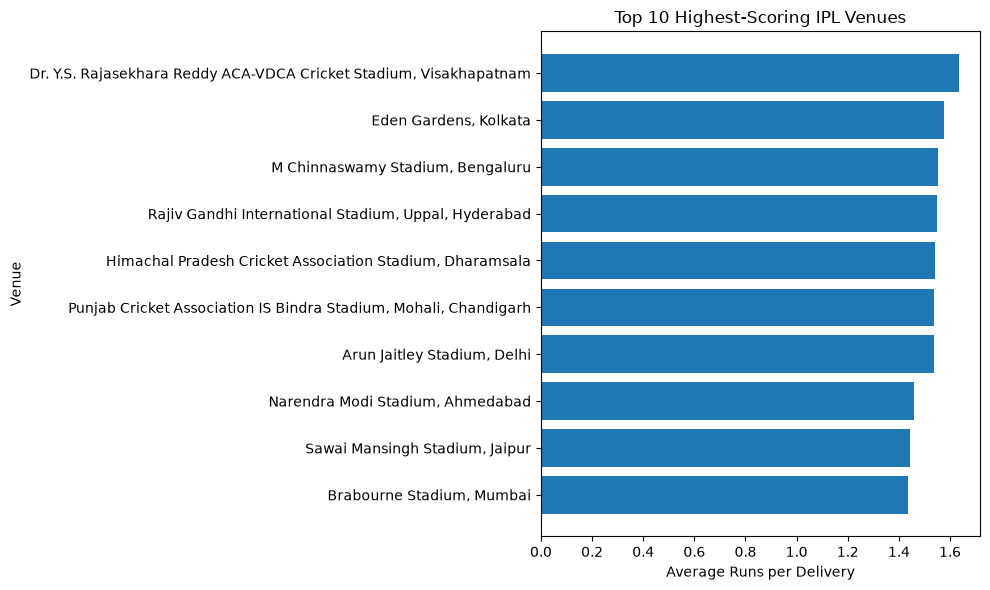

In [203]:
top_venues = venue_stats.head(10).sort_values("runs_per_delivery")

plt.figure(figsize=(10, 6))

plt.barh(
    top_venues.index,
    top_venues["runs_per_delivery"]
)

plt.title("Top 10 Highest-Scoring IPL Venues")
plt.xlabel("Average Runs per Delivery")
plt.ylabel("Venue")

plt.tight_layout()
plt.show()

### Filtering Reliable Venues

Some venues have fewer matches in the available dataset, which can make their scoring rate less representative.

Therefore, venues with at least 10 matches were selected for the final comparison.

This provides a more consistent basis for identifying relatively high-scoring and lower-scoring venues.

In [204]:
reliable_venues = venue_stats[
    venue_stats["matches"] >= 10
].copy()

reliable_venues = reliable_venues.sort_values(
    "runs_per_delivery",
    ascending=False
)

reliable_venues.head(10)

,total_runs,deliveries,matches,runs_per_delivery
stadium,,,,
"Eden Gardens, Kolkata",6436,4081,17,1.577064
"M Chinnaswamy Stadium, Bengaluru",5322,3423,14,1.554777
"Rajiv Gandhi International Stadium, Uppal, Hyderabad",5271,3404,14,1.548472
"Arun Jaitley Stadium, Delhi",6091,3963,16,1.536967
"Narendra Modi Stadium, Ahmedabad",8625,5914,25,1.458404
"Sawai Mansingh Stadium, Jaipur",3421,2370,10,1.443460
"Brabourne Stadium, Mumbai",5463,3807,16,1.434988
"Wankhede Stadium, Mumbai",15587,10915,45,1.428035
"Dr DY Patil Sports Academy, Mumbai",6573,4905,20,1.340061


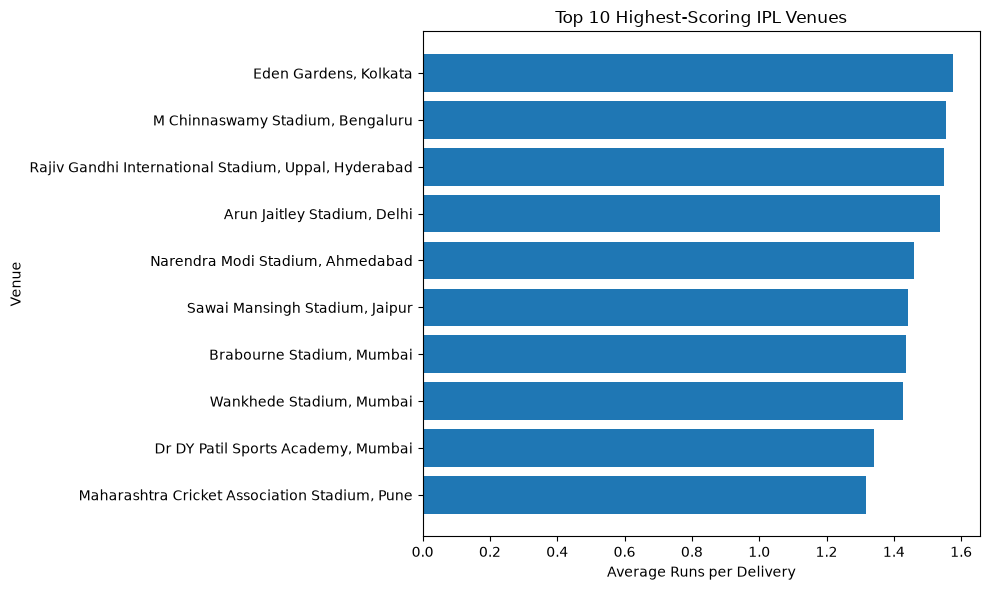

In [205]:
top_reliable_venues = reliable_venues.head(10).sort_values(
    "runs_per_delivery"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_reliable_venues.index,
    top_reliable_venues["runs_per_delivery"]
)

plt.title("Top 10 Highest-Scoring IPL Venues")
plt.xlabel("Average Runs per Delivery")
plt.ylabel("Venue")

plt.tight_layout()
plt.show()

### Visualizing Venue Scoring Rates

The top venues were visualized using runs per delivery.

A higher runs-per-delivery value indicates a relatively higher scoring rate in the available dataset.

Among the venues with at least 10 matches, Eden Gardens, M Chinnaswamy Stadium, Rajiv Gandhi International Stadium, and Arun Jaitley Stadium recorded some of the highest scoring rates.

Venue scoring can provide useful context when interpreting player performance, since batting conditions can vary across stadiums.

### Key Observation

Eden Gardens recorded the highest runs-per-delivery rate among the reliable venues in this dataset, followed by M Chinnaswamy Stadium and Rajiv Gandhi International Stadium.

However, venue scoring is used as supporting context rather than evidence that a particular venue directly improves player performance.

In [206]:
matches["pitch_type"].value_counts(dropna=False)

pitch_type
Batting-friendly    36071
Balanced            34659
Spin-friendly        7059
Sluggish             5301
Name: count, dtype: int64

## 11. Match Condition Analysis

Match conditions can influence scoring patterns and provide additional context for player performance.

The available match dataset contains several condition-related variables:

- Pitch type
- Grass cover
- Moisture
- Dew prediction
- Bounce & carry

For each condition, runs per delivery is used to compare scoring rates across categories.

These analyses show associations in the available data and should not be interpreted as proof that a specific condition directly causes higher or lower scoring.

In [207]:
pitch_stats = (
    matches.groupby("pitch_type")
    .agg(
        total_runs=("runs_total", "sum"),
        deliveries=("runs_total", "count"),
        matches=("match_id", "nunique")
    )
)

pitch_stats["runs_per_delivery"] = (
    pitch_stats["total_runs"] /
    pitch_stats["deliveries"]
)

pitch_stats.sort_values(
    "runs_per_delivery",
    ascending=False
)

,total_runs,deliveries,matches,runs_per_delivery
pitch_type,,,,
Balanced,49292,34659,143,1.422199
Batting-friendly,50799,36071,150,1.408306
Sluggish,6924,5301,22,1.306169
Spin-friendly,9179,7059,29,1.300326


### Pitch Type Observation

Balanced pitches recorded the highest runs per delivery in the available dataset, followed by batting-friendly pitches.

Sluggish and spin-friendly pitches recorded relatively lower scoring rates.

These results provide general scoring context for the matches in the dataset and do not establish a causal relationship between pitch type and scoring.

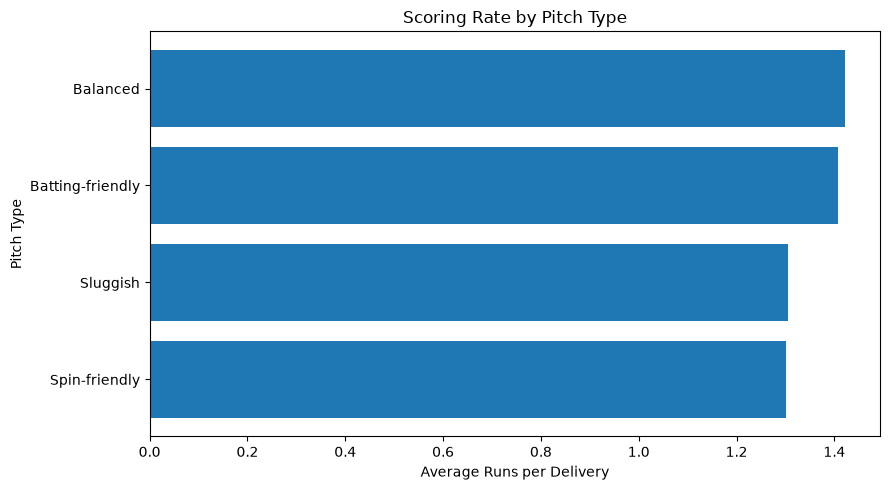

In [208]:
pitch_plot = pitch_stats.sort_values("runs_per_delivery")

plt.figure(figsize=(9, 5))

plt.barh(
    pitch_plot.index,
    pitch_plot["runs_per_delivery"]
)

plt.title("Scoring Rate by Pitch Type")
plt.xlabel("Average Runs per Delivery")
plt.ylabel("Pitch Type")

plt.tight_layout()
plt.show()

In [209]:
matches["grass_cover"].value_counts(dropna=False)

grass_cover
Medium    45245
Low       37845
Name: count, dtype: int64

In [210]:
grass_stats = (
    matches.groupby("grass_cover")
    .agg(
        total_runs=("runs_total", "sum"),
        deliveries=("runs_total", "count"),
        matches=("match_id", "nunique")
    )
)

grass_stats["runs_per_delivery"] = (
    grass_stats["total_runs"] /
    grass_stats["deliveries"]
)

grass_stats.sort_values(
    "runs_per_delivery",
    ascending=False
)

,total_runs,deliveries,matches,runs_per_delivery
grass_cover,,,,
Medium,63803,45245,187,1.410167
Low,52391,37845,157,1.384357


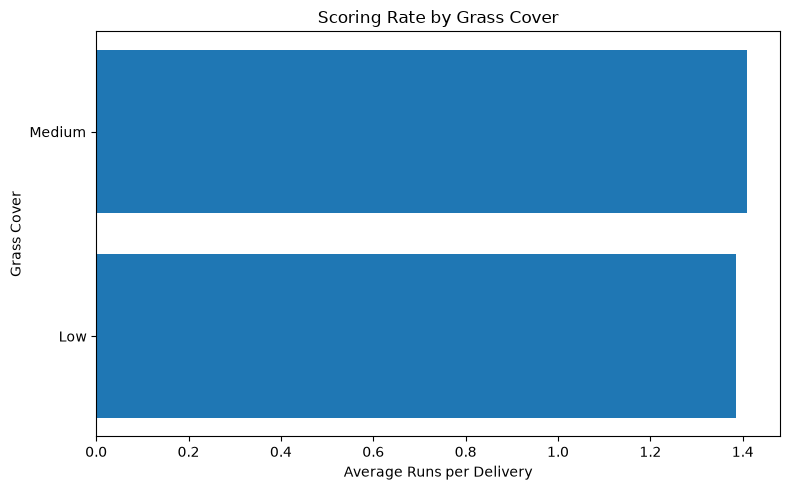

In [211]:
grass_plot = grass_stats.sort_values("runs_per_delivery")

plt.figure(figsize=(8, 5))

plt.barh(
    grass_plot.index,
    grass_plot["runs_per_delivery"]
)

plt.title("Scoring Rate by Grass Cover")
plt.xlabel("Average Runs per Delivery")
plt.ylabel("Grass Cover")

plt.tight_layout()
plt.show()

In [212]:
matches["moisture"].value_counts(dropna=False)

moisture
Low       47374
Medium    35716
Name: count, dtype: int64

In [213]:
moisture_stats = (
    matches.groupby("moisture")
    .agg(
        total_runs=("runs_total", "sum"),
        deliveries=("runs_total", "count"),
        matches=("match_id", "nunique")
    )
)

moisture_stats["runs_per_delivery"] = (
    moisture_stats["total_runs"] /
    moisture_stats["deliveries"]
)

moisture_stats.sort_values(
    "runs_per_delivery",
    ascending=False
)

,total_runs,deliveries,matches,runs_per_delivery
moisture,,,,
Medium,51417,35716,148,1.439607
Low,64777,47374,196,1.367353


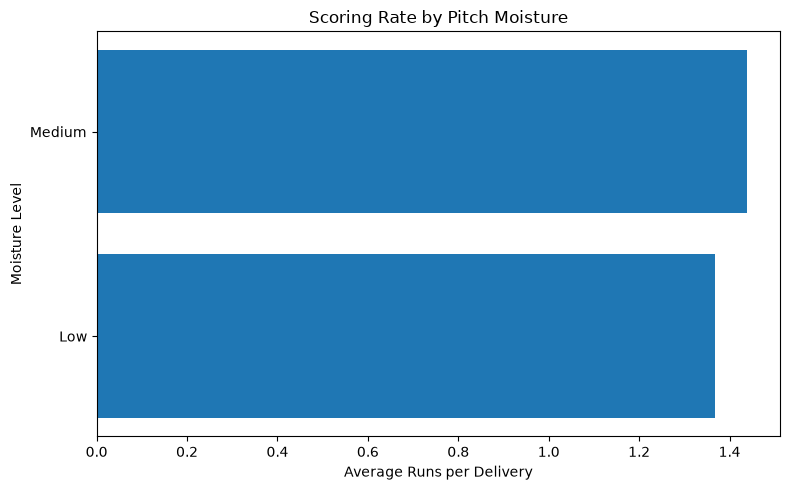

In [214]:
moisture_plot = moisture_stats.sort_values("runs_per_delivery")

plt.figure(figsize=(8, 5))

plt.barh(
    moisture_plot.index,
    moisture_plot["runs_per_delivery"]
)

plt.title("Scoring Rate by Pitch Moisture")
plt.xlabel("Average Runs per Delivery")
plt.ylabel("Moisture Level")

plt.tight_layout()
plt.show()

In [215]:
matches["dew_prediction"].value_counts(dropna=False)

dew_prediction
Moderate    39075
High        36956
Low          7059
Name: count, dtype: int64

In [216]:
dew_stats = (
    matches.groupby("dew_prediction")
    .agg(
        total_runs=("runs_total", "sum"),
        deliveries=("runs_total", "count"),
        matches=("match_id", "nunique")
    )
)

dew_stats["runs_per_delivery"] = (
    dew_stats["total_runs"] /
    dew_stats["deliveries"]
)

dew_stats.sort_values(
    "runs_per_delivery",
    ascending=False
)

,total_runs,deliveries,matches,runs_per_delivery
dew_prediction,,,,
Moderate,55696,39075,162,1.425361
High,51319,36956,153,1.388651
Low,9179,7059,29,1.300326


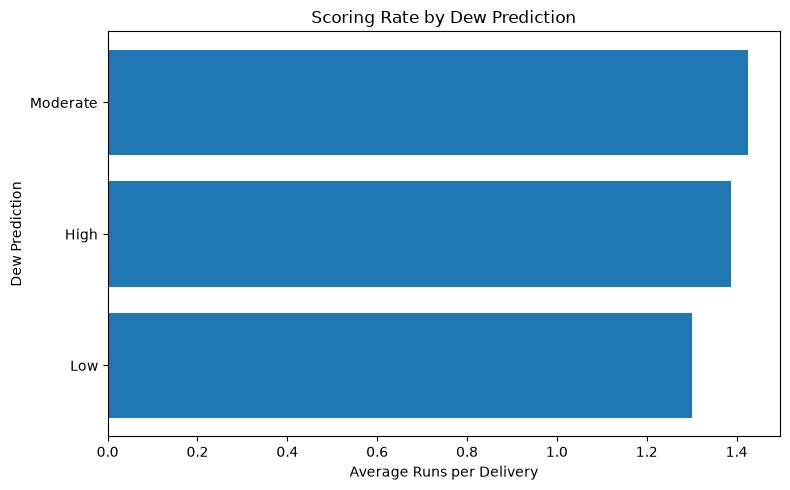

In [217]:
dew_plot = dew_stats.sort_values("runs_per_delivery")

plt.figure(figsize=(8, 5))

plt.barh(
    dew_plot.index,
    dew_plot["runs_per_delivery"]
)

plt.title("Scoring Rate by Dew Prediction")
plt.xlabel("Average Runs per Delivery")
plt.ylabel("Dew Prediction")

plt.tight_layout()
plt.show()

In [218]:
matches["bounce_and_carry"].value_counts(dropna=False)

bounce_and_carry
True bounce    40367
Consistent     25130
Low            12292
Sluggish        5301
Name: count, dtype: int64

In [219]:
bounce_stats = (
    matches.groupby("bounce_and_carry")
    .agg(
        total_runs=("runs_total", "sum"),
        deliveries=("runs_total", "count"),
        matches=("match_id", "nunique")
    )
)

bounce_stats["runs_per_delivery"] = (
    bounce_stats["total_runs"] /
    bounce_stats["deliveries"]
)

bounce_stats.sort_values(
    "runs_per_delivery",
    ascending=False
)

,total_runs,deliveries,matches,runs_per_delivery
bounce_and_carry,,,,
Consistent,36906,25130,104,1.468603
True bounce,56431,40367,167,1.397949
Sluggish,6924,5301,22,1.306169
Low,15933,12292,51,1.296209


### Overall Match Condition Observations

Across the available match-condition variables, scoring rates varied between different categories.

- Medium moisture recorded a higher scoring rate than low moisture.
- Moderate dew prediction recorded a higher scoring rate than high or low dew prediction.
- Consistent bounce and carry recorded the highest scoring rate among the bounce categories.
- Medium grass cover recorded a slightly higher scoring rate than low grass cover.

These observations provide additional context for understanding scoring conditions across IPL venues and matches.

The results represent associations within the available dataset and may also be influenced by venue, teams, opposition, match situation, and other factors.

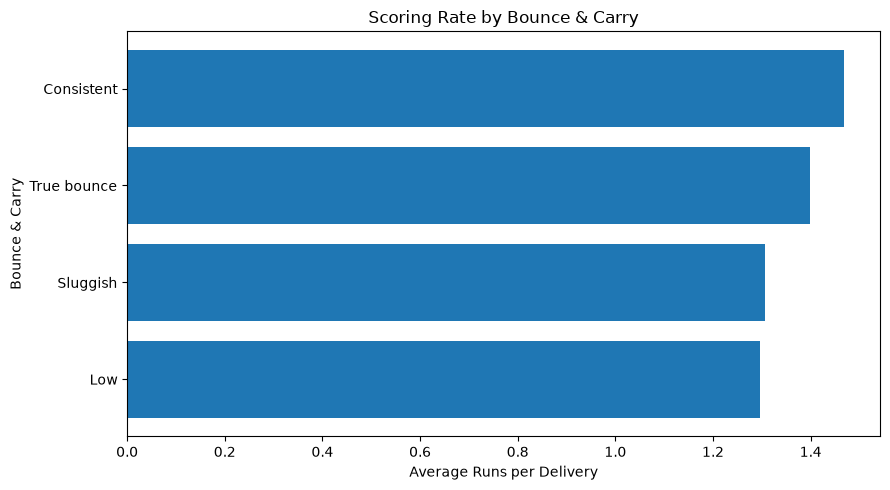

In [220]:
bounce_plot = bounce_stats.sort_values("runs_per_delivery")

plt.figure(figsize=(9, 5))

plt.barh(
    bounce_plot.index,
    bounce_plot["runs_per_delivery"]
)

plt.title("Scoring Rate by Bounce & Carry")
plt.xlabel("Average Runs per Delivery")
plt.ylabel("Bounce & Carry")

plt.tight_layout()
plt.show()

In [221]:
print("Pitch Type")
display(pitch_stats)

print("\nGrass Cover")
display(grass_stats)

print("\nMoisture")
display(moisture_stats)

print("\nDew Prediction")
display(dew_stats)

print("\nBounce & Carry")
display(bounce_stats)

Pitch Type


,total_runs,deliveries,matches,runs_per_delivery
pitch_type,,,,
Balanced,49292,34659,143,1.422199
Batting-friendly,50799,36071,150,1.408306
Sluggish,6924,5301,22,1.306169
Spin-friendly,9179,7059,29,1.300326



Grass Cover


,total_runs,deliveries,matches,runs_per_delivery
grass_cover,,,,
Low,52391,37845,157,1.384357
Medium,63803,45245,187,1.410167



Moisture


,total_runs,deliveries,matches,runs_per_delivery
moisture,,,,
Low,64777,47374,196,1.367353
Medium,51417,35716,148,1.439607



Dew Prediction


,total_runs,deliveries,matches,runs_per_delivery
dew_prediction,,,,
High,51319,36956,153,1.388651
Low,9179,7059,29,1.300326
Moderate,55696,39075,162,1.425361



Bounce & Carry


,total_runs,deliveries,matches,runs_per_delivery
bounce_and_carry,,,,
Consistent,36906,25130,104,1.468603
Low,15933,12292,51,1.296209
Sluggish,6924,5301,22,1.306169
True bounce,56431,40367,167,1.397949


In [222]:
impact_batting_stats["match_id"] = impact_batting_stats["match_id"].astype(int)

impact_batting_venue = impact_batting_stats.merge(
    matches[["match_id", "stadium"]].drop_duplicates("match_id"),
    on="match_id",
    how="left"
)

impact_batting_venue.head()

,match_id,date_x,team,player_in,player_out,impact_over,date_y,batter,batting_team,total_runs,times_out,balls_faced,wickets,runs_given,overs_bowled,contribution_type,strike_rate,stadium
0,1359475,2023-03-31,Gujarat Titans,B Sai Sudharsan,KS Williamson,3.6,2023-03-31,B Sai Sudharsan,Gujarat Titans,22.0,1.0,17.0,NaN,NaN,NaN,Batting,129.411765,"Narendra Modi Stadium, Ahmedabad"
1,1359476,2023-04-01,Kolkata Knight Riders,VR Iyer,CV Varun,2.1,2023-04-01,VR Iyer,Kolkata Knight Riders,34.0,1.0,29.0,NaN,NaN,NaN,Batting,117.241379,"Punjab Cricket Association IS Bindra Stadium, ..."
2,1359477,2023-04-01,Delhi Capitals,Aman Hakim Khan,KK Ahmed,19.1,2023-04-01,Aman Hakim Khan,Delhi Capitals,4.0,1.0,5.0,NaN,NaN,NaN,Batting,80.000000,Bharat Ratna Shri Atal Bihari Vajpayee Ekana C...
3,1359477,2023-04-01,Lucknow Super Giants,K Gowtham,A Badoni,19.6,2023-04-01,K Gowtham,Lucknow Super Giants,6.0,0.0,1.0,0.0,22.0,4.0,Both,600.000000,Bharat Ratna Shri Atal Bihari Vajpayee Ekana C...
4,1359478,2023-04-02,Sunrisers Hyderabad,Abdul Samad,Fazalhaq Farooqi,9.4,2023-04-02,Abdul Samad,Sunrisers Hyderabad,32.0,0.0,33.0,NaN,NaN,NaN,Batting,96.969697,"Rajiv Gandhi International Stadium, Uppal, Hyd..."


In [223]:
venue_scoring = reliable_venues[
    ["runs_per_delivery"]
].copy()

venue_scoring["venue_category"] = venue_scoring[
    "runs_per_delivery"
].apply(
    lambda x: "High-scoring" if x >= venue_scoring["runs_per_delivery"].median()
    else "Lower-scoring"
)

venue_scoring.head(10)


,runs_per_delivery,venue_category
stadium,,
"Eden Gardens, Kolkata",1.577064,High-scoring
"M Chinnaswamy Stadium, Bengaluru",1.554777,High-scoring
"Rajiv Gandhi International Stadium, Uppal, Hyderabad",1.548472,High-scoring
"Arun Jaitley Stadium, Delhi",1.536967,High-scoring
"Narendra Modi Stadium, Ahmedabad",1.458404,High-scoring
"Sawai Mansingh Stadium, Jaipur",1.443460,High-scoring
"Brabourne Stadium, Mumbai",1.434988,High-scoring
"Wankhede Stadium, Mumbai",1.428035,High-scoring
"Dr DY Patil Sports Academy, Mumbai",1.340061,Lower-scoring


In [224]:
impact_batting_venue = impact_batting_venue.merge(
    venue_scoring[["venue_category"]],
    left_on="stadium",
    right_index=True,
    how="left"
)

impact_batting_venue[
    ["player_in", "stadium", "total_runs", "balls_faced", "venue_category"]
].head(10)

,player_in,stadium,total_runs,balls_faced,venue_category
0,B Sai Sudharsan,"Narendra Modi Stadium, Ahmedabad",22.0,17.0,High-scoring
1,VR Iyer,"Punjab Cricket Association IS Bindra Stadium, ...",34.0,29.0,NaN
2,Aman Hakim Khan,Bharat Ratna Shri Atal Bihari Vajpayee Ekana C...,4.0,5.0,Lower-scoring
3,K Gowtham,Bharat Ratna Shri Atal Bihari Vajpayee Ekana C...,6.0,1.0,Lower-scoring
4,Abdul Samad,"Rajiv Gandhi International Stadium, Uppal, Hyd...",32.0,33.0,High-scoring
5,A Badoni,"MA Chidambaram Stadium, Chepauk, Chennai",23.0,19.0,Lower-scoring
6,V Shankar,"Arun Jaitley Stadium, Delhi",29.0,24.0,High-scoring
7,Dhruv Jurel,"Barsapara Cricket Stadium, Guwahati",32.0,16.0,NaN
8,Anuj Rawat,"Eden Gardens, Kolkata",1.0,5.0,High-scoring
9,PP Shaw,"Barsapara Cricket Stadium, Guwahati",0.0,3.0,NaN


In [225]:
player_comparison.to_csv(
    "../data/impact_player_batting_comparison.csv"
)

bowling_comparison.to_csv(
    "../data/impact_player_bowling_comparison.csv"
)

venue_stats.to_csv(
    "../data/venue_scoring_stats.csv"
)

pitch_stats.to_csv(
    "../data/pitch_type_stats.csv"
)

In [226]:
grass_stats.to_csv("../data/grass_cover_stats.csv")
moisture_stats.to_csv("../data/moisture_stats.csv")
dew_stats.to_csv("../data/dew_prediction_stats.csv")
bounce_stats.to_csv("../data/bounce_carry_stats.csv")

## 12. Key Findings

The analysis produced the following key findings:

### Impact Player Usage
- P Simran Singh was the most frequently used Impact Player during 2023–2025, followed by Suyash Sharma and S Dube.
- Impact Player usage varied considerably across players and teams.

### Impact Player Batting
- Among players with at least 5 Impact Player batting appearances, VR Iyer and P Simran Singh showed an increase in average runs compared with their normal appearances.
- The remaining qualified players recorded lower average runs as Impact Players.
- This indicates that the Impact Player role does not automatically lead to improved batting performance.

### Impact Player Bowling
- M Pathirana showed the strongest improvement in the bowling comparison, with better wickets per appearance and lower economy as an Impact Player.
- NT Ellis and Suyash Sharma also showed improved bowling patterns.
- VG Arora recorded similar wickets per appearance but a higher economy as an Impact Player.

### Venue and Match Conditions
- Eden Gardens recorded the highest runs-per-delivery rate among the reliable venues in the available dataset.
- Balanced pitches, medium moisture, moderate dew prediction, and consistent bounce & carry were associated with relatively higher scoring rates in their respective categories.

Overall, the analysis shows that Impact Player effectiveness varies by player and role, while venue and match conditions provide useful context for interpreting performance.

## 13. Limitations

- The match-condition dataset covers IPL 2020–2024 and only partial 2025 data, ending on 25 March 2025.
- Impact Player analysis covers the 2023–2025 seasons.
- Some Impact Players have only a small number of appearances, so comparisons can be sensitive to individual matches.
- Player performance can be influenced by batting position, bowling role, opposition, match situation, team strategy, and venue.
- The analysis identifies associations and observed patterns; it does not prove that being used as an Impact Player causes a change in performance.
- Player name variations across datasets may affect matching in some cases.
- The analysis uses available scorecard-level statistics and does not capture every tactical factor involved in an Impact Player decision.